# AISE 4010 Course Project – Stages 1–2 (Lab 6 and Lab 9)
## Beijing PM2.5: one-hour-ahead forecasting with a naive baseline, MLP, 1D CNN, RNN, LSTM, GRU and TCN

In [1]:
import os
import time
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

SEED = 42
tf.keras.utils.set_random_seed(SEED)
print("Seed:", SEED)

Seed: 42


## 1. Data

| | |
|---|---|
| Source | UCI Beijing PM2.5 data, `pollution.csv` (dataset #23) |
| Target | `pm2.5` |
| Unit | µg/m³ |
| Native frequency | hourly |
| Resampling rule | none needed (hourly index checked below) |
| Horizon | 1 hour |
| Lookback | 24 hours |
| Split | chronological 60% train / 20% validation / 20% test |

In [2]:
DATA_URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pollution.csv"
DATA_FILE = "data/pollution.csv"

if not os.path.exists(DATA_FILE):
    urllib.request.urlretrieve(DATA_URL, DATA_FILE)

df = pd.read_csv(DATA_FILE)
df["DATE"] = pd.to_datetime(df[["year", "month", "day", "hour"]])
df = df.sort_values("DATE").set_index("DATE")

series = df["pm2.5"].copy()

In [3]:
is_na = series.isna()

print("Rows:", len(df))
print("Coverage:", df.index.min(), "to", df.index.max())
print("Duplicate timestamps:", df.index.duplicated().sum())
print("Gaps in the hourly index:", (df.index.to_series().diff().dropna() != pd.Timedelta(hours=1)).sum())
print("Missing pm2.5:", is_na.sum(), f"({is_na.mean():.1%})")
print("Leading rows with no reading:", series.index.get_loc(series.first_valid_index()))
print()
print(series.describe())

assert df.index.is_unique and df.index.is_monotonic_increasing

Rows: 43824
Coverage: 2010-01-01 00:00:00 to 2014-12-31 23:00:00
Duplicate timestamps: 0
Gaps in the hourly index: 0
Missing pm2.5: 2067 (4.7%)
Leading rows with no reading: 24

count    41757.000000
mean        98.613215
std         92.050387
min          0.000000
25%         29.000000
50%         72.000000
75%        137.000000
max        994.000000
Name: pm2.5, dtype: float64


The first 24 rows have no reading, so the series starts at the first observed value.

In [4]:
series = series.loc[series.first_valid_index():]
print("Series used:", series.index.min(), "to", series.index.max(), "|", len(series), "hours")

Series used: 2010-01-02 00:00:00 to 2014-12-31 23:00:00 | 43800 hours


## 2. Chronological split
Split the raw series first. No imputation, scaling or windows before this step.

In [5]:
n = len(series)
train_end = int(0.60 * n)
val_end = int(0.80 * n)

train_raw = series.iloc[:train_end].copy()
val_raw   = series.iloc[train_end:val_end].copy()
test_raw  = series.iloc[val_end:].copy()

split_table = pd.DataFrame({
    "start": [s.index.min() for s in (train_raw, val_raw, test_raw)],
    "end": [s.index.max() for s in (train_raw, val_raw, test_raw)],
    "hours": [len(s) for s in (train_raw, val_raw, test_raw)],
    "missing": [s.isna().sum() for s in (train_raw, val_raw, test_raw)]
}, index=["Train", "Validation", "Test"])
display(split_table)

,start,end,hours,missing
Train,2010-01-02,2012-12-31 23:00:00,26280,1862
Validation,2013-01-01,2013-12-31 23:00:00,8760,82
Test,2014-01-01,2014-12-31 23:00:00,8760,99


## 3. Exploratory analysis

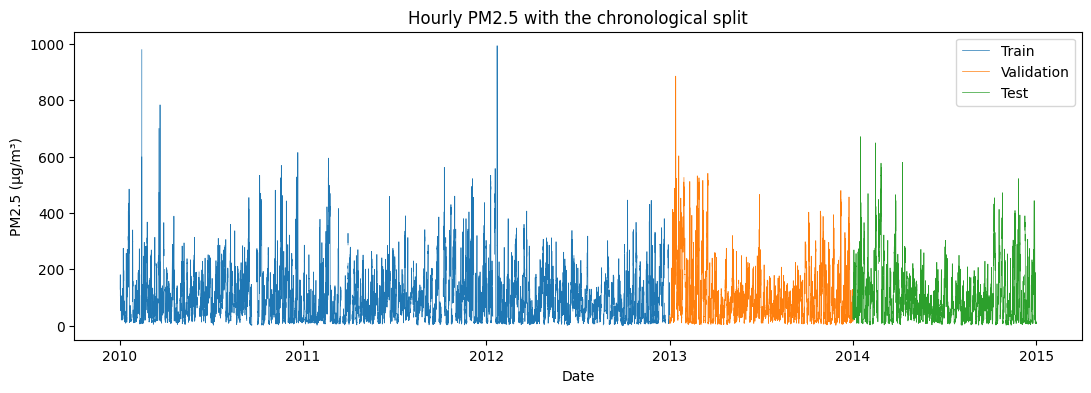

In [6]:
plt.figure(figsize=(13, 4))
plt.plot(train_raw, linewidth=0.5, label="Train")
plt.plot(val_raw, linewidth=0.5, label="Validation")
plt.plot(test_raw, linewidth=0.5, label="Test")
plt.xlabel("Date")
plt.ylabel("PM2.5 (µg/m³)")
plt.title("Hourly PM2.5 with the chronological split")
plt.legend()
plt.show()

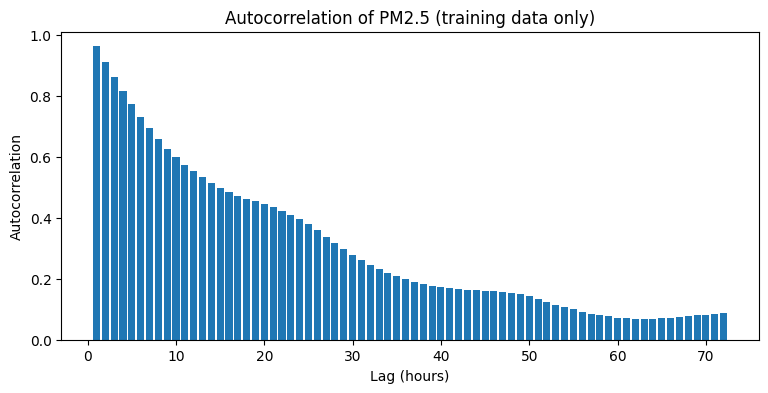

In [7]:
acf = [train_raw.autocorr(lag) for lag in range(1, 73)]

plt.figure(figsize=(9, 4))
plt.bar(range(1, 73), acf)
plt.xlabel("Lag (hours)")
plt.ylabel("Autocorrelation")
plt.title("Autocorrelation of PM2.5 (training data only)")
plt.show()

## 4. Imputation, scaling and windows
Forward fill after splitting. A validation/test block may inherit the last value of the block before it, because that past observation is already known.

In [8]:
train = train_raw.ffill()

val = pd.concat([train.iloc[-1:], val_raw]).ffill().iloc[1:]
test = pd.concat([val.iloc[-1:], test_raw]).ffill().iloc[1:]

print(train.isna().sum(), val.isna().sum(), test.isna().sum())
assert train.notna().all() and val.notna().all() and test.notna().all()

0 0 0


In [9]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

train_scaled = scaler.fit_transform(
    train.to_numpy().reshape(-1, 1)
).ravel()

val_scaled = scaler.transform(
    val.to_numpy().reshape(-1, 1)
).ravel()

test_scaled = scaler.transform(
    test.to_numpy().reshape(-1, 1)
).ravel()

In [10]:
def make_windows(values, lookback):
    X, y = [], []
    for i in range(lookback, len(values)):
        X.append(values[i-lookback:i])
        y.append(values[i])
    return np.asarray(X), np.asarray(y)

LOOKBACK = 24

X_train, y_train = make_windows(train_scaled, LOOKBACK)
X_val,   y_val   = make_windows(val_scaled, LOOKBACK)
X_test,  y_test  = make_windows(test_scaled, LOOKBACK)

val_observed = val_raw.iloc[LOOKBACK:].notna().to_numpy()
test_observed = test_raw.iloc[LOOKBACK:].notna().to_numpy()
X_val, y_val = X_val[val_observed], y_val[val_observed]
X_test, y_test = X_test[test_observed], y_test[test_observed]

print("X_train:", X_train.shape, "y_train:", y_train.shape)
print("X_val:  ", X_val.shape,   "y_val:", y_val.shape)
print("X_test: ", X_test.shape,  "y_test:", y_test.shape)
print("CNN input (add channel axis):", X_train[..., np.newaxis].shape)
print("\nFirst training input:", X_train[0])
print("First training target:", y_train[0])

X_train: (26256, 24) y_train: (26256,)
X_val:   (8654, 24) y_val: (8654,)
X_test:  (8637, 24) y_test: (8637,)
CNN input (add channel axis): (26256, 24, 1)

First training input: [0.36859129 0.58395565 0.70864028 0.95800954 0.47060598 0.14189196
 0.09655209 0.31191645 0.26657659 0.40259619 0.49327592 0.62929552
 0.58395565 0.76531511 0.69730531 0.65196545 0.70864028 0.76531511
 0.83332491 0.59529062 0.65196545 0.76531511 0.67463538 0.33458639]
First training target: -0.07347240746272389


## 5. Naive baseline
Predict the next hour with the latest available hour, which is the last value of each 24-hour window.

In [11]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

def inverse_1d(values, fitted_scaler):
    return fitted_scaler.inverse_transform(
        np.asarray(values).reshape(-1, 1)
    ).ravel()

val_actual = inverse_1d(y_val, scaler)

val_naive_scaled = X_val[:, -1]
val_naive = inverse_1d(val_naive_scaled, scaler)

baseline_val_mae = mean_absolute_error(val_actual, val_naive)
baseline_val_rmse = mean_squared_error(val_actual, val_naive) ** 0.5

print("Naive validation MAE :", baseline_val_mae)
print("Naive validation RMSE:", baseline_val_rmse)

Naive validation MAE : 13.235035821585393
Naive validation RMSE: 24.896504052340262


## 6. MLP and 1D CNN with grid search
Both models use the same windows, loss (MSE), optimizer (Adam), batch size, early stopping and validation set. The best configuration is the one with the lowest validation RMSE.

```text
MLP: units = [16, 32], learning_rate = [0.01, 0.001]
CNN: filters = [8, 16], kernel_size = [3, 7]
```

In [12]:
from itertools import product
from tensorflow.keras import Sequential, Input
from tensorflow.keras.layers import Dense, Conv1D, MaxPooling1D, Flatten
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

def build_mlp(units, lr):
    model = Sequential([
        Input(shape=(LOOKBACK,)),
        Dense(units, activation="relu"),
        Dense(1)
    ])
    model.compile(optimizer=Adam(learning_rate=lr), loss="mse")
    return model

def build_1d_cnn(filters, kernel_size):
    model = Sequential([
        Input(shape=(LOOKBACK, 1)),
        Conv1D(filters=filters, kernel_size=kernel_size, activation="relu", padding="same"),
        MaxPooling1D(pool_size=2),
        Flatten(),
        Dense(16, activation="relu"),
        Dense(1)
    ])
    model.compile(optimizer=Adam(learning_rate=0.001), loss="mse")
    return model

In [13]:
grid = {
    "units": [16, 32],
    "lr": [0.01, 0.001]
}

mlp_results = []
mlp_histories = {}

for units, lr in product(grid["units"], grid["lr"]):

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)

    candidate = build_mlp(units, lr)

    es = EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    )

    candidate_history = candidate.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=50,
        batch_size=32,
        shuffle=False,
        callbacks=[es],
        verbose=0
    )

    pred_scaled = candidate.predict(X_val, verbose=0).ravel()
    pred = inverse_1d(pred_scaled, scaler)

    rmse = mean_squared_error(val_actual, pred) ** 0.5

    mlp_histories[(units, lr)] = candidate_history.history
    mlp_results.append({
        "units": units,
        "lr": lr,
        "validation_RMSE": rmse,
        "best_epoch": int(np.argmin(candidate_history.history["val_loss"])) + 1,
        "epochs_trained": len(candidate_history.history["loss"])
    })

mlp_results = pd.DataFrame(mlp_results).sort_values(
    ["validation_RMSE", "units", "lr"]
).reset_index(drop=True)

display(mlp_results)

best_units = int(mlp_results.iloc[0]["units"])
best_lr = float(mlp_results.iloc[0]["lr"])
best_epochs_mlp = int(mlp_results.iloc[0]["best_epoch"])

print("Best units:", best_units)
print("Best learning rate:", best_lr)
print("Final refit epochs (chosen on validation only):", best_epochs_mlp)

,units,lr,validation_RMSE,best_epoch,epochs_trained
0,32,0.001,24.268235,21,26
1,16,0.010,24.408584,7,12
2,32,0.010,24.486470,15,20
3,16,0.001,25.188316,8,13


Best units: 32
Best learning rate: 0.001
Final refit epochs (chosen on validation only): 21


In [14]:
filters_grid_1d = [8, 16]
kernel_grid_1d = [3, 7]

cnn_results = []
cnn_histories = {}

for filters, kernel_size in product(filters_grid_1d, kernel_grid_1d):

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)

    candidate = build_1d_cnn(filters, kernel_size)

    es = EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    )

    candidate_history = candidate.fit(
        X_train[..., np.newaxis], y_train,
        validation_data=(X_val[..., np.newaxis], y_val),
        epochs=50,
        batch_size=32,
        shuffle=False,
        callbacks=[es],
        verbose=0
    )

    pred_scaled = candidate.predict(X_val[..., np.newaxis], verbose=0).ravel()
    pred = inverse_1d(pred_scaled, scaler)

    rmse = mean_squared_error(val_actual, pred) ** 0.5

    cnn_histories[(filters, kernel_size)] = candidate_history.history
    cnn_results.append({
        "filters": filters,
        "kernel_size": kernel_size,
        "validation_RMSE": rmse,
        "best_epoch": int(np.argmin(candidate_history.history["val_loss"])) + 1,
        "epochs_trained": len(candidate_history.history["loss"])
    })

cnn_results = pd.DataFrame(cnn_results).sort_values(
    ["validation_RMSE", "filters", "kernel_size"]
).reset_index(drop=True)

display(cnn_results)

best_1d_filters = int(cnn_results.iloc[0]["filters"])
best_1d_kernel = int(cnn_results.iloc[0]["kernel_size"])
best_epochs_cnn = int(cnn_results.iloc[0]["best_epoch"])

print("Tie-break rule: lowest validation RMSE -> fewer filters -> smaller kernel")
print("Best 1D filters:", best_1d_filters)
print("Best 1D kernel size:", best_1d_kernel)
print("Final refit epochs (chosen on validation only):", best_epochs_cnn)

,filters,kernel_size,validation_RMSE,best_epoch,epochs_trained
0,8,3,23.874229,18,23
1,16,7,23.916864,13,18
2,16,3,24.049926,13,18
3,8,7,24.097397,36,41


Tie-break rule: lowest validation RMSE -> fewer filters -> smaller kernel
Best 1D filters: 8
Best 1D kernel size: 3
Final refit epochs (chosen on validation only): 18


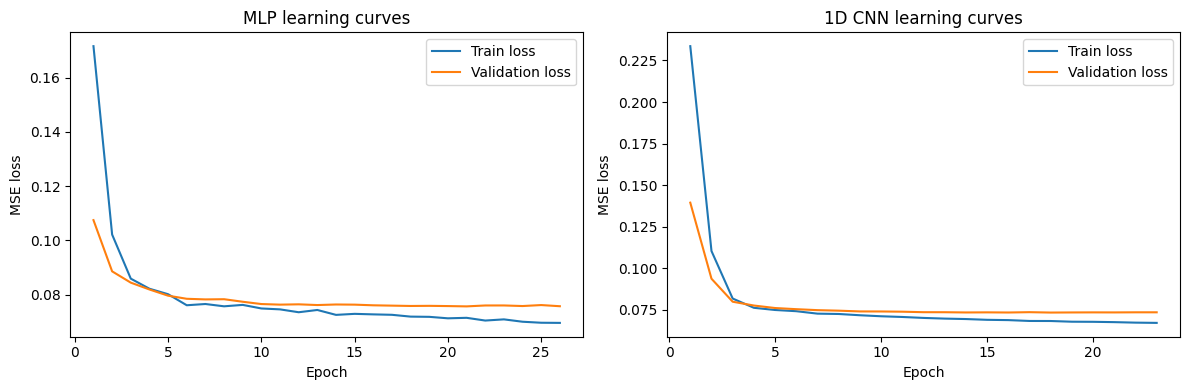

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, history, title in [
    (axes[0], mlp_histories[(best_units, best_lr)], "MLP learning curves"),
    (axes[1], cnn_histories[(best_1d_filters, best_1d_kernel)], "1D CNN learning curves")
]:
    ax.plot(np.arange(1, len(history["loss"]) + 1), history["loss"], label="Train loss")
    ax.plot(np.arange(1, len(history["val_loss"]) + 1), history["val_loss"], label="Validation loss")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("MSE loss")
    ax.set_title(title)
    ax.legend()

plt.tight_layout()
plt.show()

## 7. Final refit and test evaluation
Hyperparameters and epochs are fixed from validation. Fit a new scaler on train + validation, train a fresh model on all development windows, and evaluate the observed test targets once.

In [16]:
dev = pd.concat([train, val])

final_scaler = StandardScaler()
dev_scaled = final_scaler.fit_transform(
    dev.to_numpy().reshape(-1, 1)
).ravel()

test_scaled_final = final_scaler.transform(
    test.to_numpy().reshape(-1, 1)
).ravel()

X_dev, y_dev = make_windows(dev_scaled, LOOKBACK)
X_test_final, y_test_final = make_windows(test_scaled_final, LOOKBACK)

X_test_final = X_test_final[test_observed]
y_test_final = y_test_final[test_observed]

test_actual = inverse_1d(y_test_final, final_scaler)
test_naive = inverse_1d(X_test_final[:, -1], final_scaler)

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)

final_mlp = build_mlp(best_units, best_lr)

start = time.time()
final_mlp.fit(
    X_dev, y_dev,
    epochs=best_epochs_mlp,
    batch_size=32,
    shuffle=False,
    verbose=0
)
mlp_train_time = time.time() - start

mlp_pred = inverse_1d(final_mlp.predict(X_test_final, verbose=0).ravel(), final_scaler)

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)

final_cnn = build_1d_cnn(best_1d_filters, best_1d_kernel)

start = time.time()
final_cnn.fit(
    X_dev[..., np.newaxis], y_dev,
    epochs=best_epochs_cnn,
    batch_size=32,
    shuffle=False,
    verbose=0
)
cnn_train_time = time.time() - start

cnn_pred = inverse_1d(final_cnn.predict(X_test_final[..., np.newaxis], verbose=0).ravel(), final_scaler)

In [17]:
def test_scores(name, pred, params, train_time):
    return {
        "Model": name,
        "Parameters": params,
        "Training time (s)": train_time,
        "MAE": mean_absolute_error(test_actual, pred),
        "RMSE": mean_squared_error(test_actual, pred) ** 0.5
    }

results_final = pd.DataFrame([
    test_scores("Naive", test_naive, 0, 0.0),
    test_scores("MLP", mlp_pred, final_mlp.count_params(), mlp_train_time),
    test_scores("1D CNN", cnn_pred, final_cnn.count_params(), cnn_train_time)
])

naive_mae = results_final.loc[0, "MAE"]
naive_rmse = results_final.loc[0, "RMSE"]
results_final["MAE improvement (%)"] = 100 * (naive_mae - results_final["MAE"]) / naive_mae
results_final["RMSE improvement (%)"] = 100 * (naive_rmse - results_final["RMSE"]) / naive_rmse

display(results_final.round(3))

,Model,Parameters,Training time (s),MAE,RMSE,MAE improvement (%),RMSE improvement (%)
0,Naive,0,0.000,11.958,22.152,0.000,0.000
1,MLP,833,190.002,12.008,21.499,-0.423,2.946
2,1D CNN,1601,248.047,11.954,21.674,0.026,2.159


In [18]:
assert X_train.shape[1] == LOOKBACK and X_val.shape[1] == LOOKBACK and X_test.shape[1] == LOOKBACK
assert train_raw.index.max() < val_raw.index.min() and val_raw.index.max() < test_raw.index.min()
assert np.isclose(scaler.mean_[0], train.mean())
assert len(test_actual) == len(mlp_pred) == len(cnn_pred) == len(test_naive)
print("Smoke test passed")

Smoke test passed


## 8. Conclusion and unresolved risk
**Conclusion.** At a one-hour horizon the naive forecast (repeat the last hour) is very hard to beat. On the test set it scores MAE 11.96 and RMSE 22.15 µg/m³. The MLP (32 units, learning rate 0.001) lowers RMSE by about 2.9 % and the 1D CNN (8 filters, kernel size 3) by about 2.2 %, but neither lowers MAE meaningfully (MLP −0.4 %, CNN +0.03 %). Both networks have many more parameters than the baseline and gain only a little.

**Unresolved risk.** The gains over naive are small, the validation winner (CNN) is not the test winner (MLP), and every result comes from a single training run with one seed. We cannot yet say that either network really beats the naive baseline or that one beats the other. Next step: repeat the fits with several seeds and compare the spread.

# Stage 2 (Lab 9): recurrent family and TCN, grid-search HPO, finalist selection

Sections 1-8 above are **Stage 1** and are unchanged (their outputs are the ones recorded at the Lab 6 demo). Stage 2 adds:

| Section | Content |
|---|---|
| 9 | Stage 2 setup and environment |
| 10 | **HPO protocol (search space, budget, objective, stopping rule), written before any Stage 2 result** |
| 11 | New models: SimpleRNN, LSTM, GRU, TCN (MLP and CNN are kept) |
| 12 | Grid-search HPO for all six neural families (equal budget) |
| 13 | Finalist selection (validation only) and locking |
| 14 | Controlled comparison: every model and the baseline, same split / windows / metrics, test set evaluated once |
| 15 | Checkpoint for Stage 3 and smoke test |
| 16 | Conclusion and unresolved risk |

**Same evaluation contract as Stage 1.** Target `pm2.5`, horizon 1 hour, lookback 24 hours, chronological 60 / 20 / 20 split, forward-fill after the split, scaler fitted on training data only, univariate inputs (past PM2.5 only), only observed targets are scored.

**Why MLP and CNN are trained again here.** Training and inference times are only comparable if every model runs on the same machine in the same session. The Stage 1 numbers were produced on a different machine, so Stage 2 re-trains MLP and CNN with the same code path as the new models. Section 14 compares the re-run with the recorded Stage 1 numbers.

## 9. Stage 2 setup

In [19]:
import json, platform, sys
from pathlib import Path
import logging
import sklearn
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.layers import SimpleRNN, LSTM, GRU

tf.get_logger().setLevel(logging.ERROR)   # silence tf.function retracing warnings in the trial loops
ARTIFACTS = Path("artifacts")          # relative path: logs, config, scaler state, finalist checkpoint
ARTIFACTS.mkdir(exist_ok=True)

print("Python      :", platform.python_version(), "|", platform.platform())
print("CPU cores   :", os.cpu_count(), "(CPU only, no GPU)")
print("TensorFlow  :", tf.__version__, "| Keras", keras.__version__)
print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)

# one consistent colour per family (fixed order, never re-assigned)
COLORS = {"MLP": "#2a78d6", "CNN": "#eb6834", "RNN": "#1baf7a", "LSTM": "#eda100",
          "GRU": "#e87ba4", "TCN": "#008300", "Naive": "#898781"}
plt.rcParams.update({
    "figure.dpi": 100, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 11, "axes.labelsize": 10,
    "legend.frameon": False, "font.size": 10,
})

Python      : 3.13.18 | Linux-6.18.44-fc-v470-x86_64-with-glibc2.39
CPU cores   : 2 (CPU only, no GPU)
TensorFlow  : 2.21.0 | Keras 3.15.1
numpy 2.5.3 | pandas 3.0.5 | scikit-learn 1.9.1


## 10. HPO protocol (declared before any Stage 2 result)

Everything in this section is fixed **before** any new model is trained. Nothing here is changed after looking at results.

**Objective.** Validation RMSE in µg/m³ on the observed validation targets (the same quantity as Stage 1). The test set is not used for any choice.

**Common training recipe (identical for every model).** Same windows (24 past hours, horizon 1 h), MSE loss on scaled values, Adam, batch size 32, at most 50 epochs, early stopping on validation loss (patience 5, best weights restored), `shuffle=False`, seed 42 (`SEED`, as in Stage 1). `steps_per_execution=16` only batches Python calls for speed; each update is still one batch of 32.

**Search space and budget.** Every family gets the same budget: a 4-configuration grid, one run per configuration (24 trials in total). The MLP and CNN grids are the Stage 1 grids; the new families use a comparable grid (table below).

**Stopping rules.**
- *Per trial:* early stopping as above.
- *Per search:* the grid is run completely, with no adaptive extension and no early abandonment.

**Selection rule.** Within a family: lowest validation RMSE (tie: fewer parameters). Finalist: the family-best configuration with the lowest validation RMSE (tie: fewer parameters). The architecture name plays no role. Parameters and training time are reported next to it so that trade-offs are visible.

**Locking.** The finalist configuration, its refit epoch count and the preprocessing state are written to `artifacts/` before any Stage 2 test number is computed.

**Test-set discipline.** No Stage 2 decision uses a test number. (Stage 1 already printed test numbers for the naive baseline, MLP and CNN; they were not used for any Stage 2 choice either.) After locking, each model is refit on train + validation for the number of epochs found on validation, and evaluated once on the test set.

In [20]:
# ---- Stage 2 protocol constants (declared before any Stage 2 result) ----
MAX_EPOCHS, PATIENCE, BATCH_SIZE = 50, 5, 32
STEPS_PER_EXEC = 16                   # speed only; not a modelling choice
TCN_DILATIONS, TCN_DROPOUT = (1, 2, 4), 0.1

FAMILIES = ["MLP", "CNN", "RNN", "LSTM", "GRU", "TCN"]

SPACE = {   # search space: 4 configurations per family (MLP and CNN: the Stage 1 grids)
    "MLP":  {"units": [16, 32],   "lr": [0.01, 0.001]},
    "CNN":  {"filters": [8, 16],  "kernel_size": [3, 7], "lr": [0.001]},
    "RNN":  {"units": [16, 32],   "lr": [0.01, 0.001]},
    "LSTM": {"units": [16, 32],   "lr": [0.01, 0.001]},
    "GRU":  {"units": [16, 32],   "lr": [0.01, 0.001]},
    "TCN":  {"filters": [8, 16],  "kernel_size": [3, 5], "lr": [0.001]},
}

def n_grid(space):
    out = 1
    for values in space.values():
        out *= len(values)
    return out

budget = pd.DataFrame({
    "Search space": {f: str(SPACE[f]) for f in FAMILIES},
    "Trials": {f: n_grid(SPACE[f]) for f in FAMILIES},
})
display(budget)
print(f"Budget: {sum(n_grid(SPACE[f]) for f in FAMILIES)} validation trainings in total (seed {SEED})")
print("Objective: validation RMSE (ug/m3). Finalist = family-best configuration with the lowest validation RMSE -> tie: fewer parameters")

,Search space,Trials
MLP,"{'units': [16, 32], 'lr': [0.01, 0.001]}",4
CNN,"{'filters': [8, 16], 'kernel_size': [3, 7], 'l...",4
RNN,"{'units': [16, 32], 'lr': [0.01, 0.001]}",4
LSTM,"{'units': [16, 32], 'lr': [0.01, 0.001]}",4
GRU,"{'units': [16, 32], 'lr': [0.01, 0.001]}",4
TCN,"{'filters': [8, 16], 'kernel_size': [3, 5], 'l...",4


Budget: 24 validation trainings in total (seed 42)
Objective: validation RMSE (ug/m3). Finalist = family-best configuration with the lowest validation RMSE -> tie: fewer parameters


## 11. Models

All models read the same 24-hour windows and predict the next hour. Shapes: `X` is `(samples, 24)` for the MLP and `(samples, 24, 1)` (samples, timesteps, features) for CNN, RNN, LSTM, GRU and TCN.

| Family | Architecture |
|---|---|
| MLP, CNN | exactly the Stage 1 architectures |
| RNN | `SimpleRNN(units)` -> `Dense(1)` |
| LSTM | `LSTM(units)` -> `Dense(1)` |
| GRU | `GRU(units)` -> `Dense(1)` |
| TCN | residual blocks as in Assignment 3 (two causal dilated `Conv1D`, each followed by layer normalisation, ReLU and dropout, plus a shortcut), one block per dilation in `(1, 2, 4)`, then the newest time step -> `Dense(1)` |

The TCN receptive field is $r = 1 + 2(k-1)\sum_i d_i$. It must cover the 24-hour window: $k=3$ gives $r=29$ and $k=5$ gives $r=57$.

In [21]:
def arch_mlp(units):
    return Sequential([Input(shape=(LOOKBACK,)), Dense(units, activation="relu"), Dense(1)])

def arch_cnn(filters, kernel_size):
    return Sequential([
        Input(shape=(LOOKBACK, 1)),
        Conv1D(filters=filters, kernel_size=kernel_size, activation="relu", padding="same"),
        MaxPooling1D(pool_size=2), Flatten(), Dense(16, activation="relu"), Dense(1)])

def arch_recurrent(cell, units):
    return Sequential([Input(shape=(LOOKBACK, 1)), cell(units), Dense(1)])

def tcn_block(x, filters, kernel_size, dilation, name):
    shortcut = x if x.shape[-1] == filters else layers.Conv1D(filters, 1)(x)   # 1x1 conv when channels differ
    for _ in range(2):                                                         # two causal dilated convs per block
        x = layers.Conv1D(filters, kernel_size, padding="causal", dilation_rate=dilation)(x)
        x = layers.LayerNormalization()(x)
        x = layers.Activation("relu")(x)
        x = layers.Dropout(TCN_DROPOUT)(x)
    return layers.Activation("relu", name=name)(layers.Add()([shortcut, x]))

def arch_tcn(filters, kernel_size):
    inputs = keras.Input(shape=(LOOKBACK, 1))
    x = inputs
    for i, d in enumerate(TCN_DILATIONS, start=1):
        x = tcn_block(x, filters, kernel_size, d, name=f"block{i}")
    outputs = layers.Dense(1)(x[:, -1, :])                                     # newest time step -> forecast
    return keras.Model(inputs, outputs, name="tcn")

BUILDERS = {
    "MLP":  lambda c: arch_mlp(c["units"]),
    "CNN":  lambda c: arch_cnn(c["filters"], c["kernel_size"]),
    "RNN":  lambda c: arch_recurrent(SimpleRNN, c["units"]),
    "LSTM": lambda c: arch_recurrent(LSTM, c["units"]),
    "GRU":  lambda c: arch_recurrent(GRU, c["units"]),
    "TCN":  lambda c: arch_tcn(c["filters"], c["kernel_size"]),
}

def inputs_for(family, X):
    return X if family == "MLP" else X[..., np.newaxis]

def cfg_str(cfg):
    return ", ".join(f"{k}={v}" for k, v in cfg.items())

def cfg_key(cfg):
    return json.dumps(cfg, sort_keys=True)

def new_model(family, cfg, seed):
    keras.backend.clear_session()
    keras.utils.set_random_seed(seed)
    model = BUILDERS[family](cfg)
    model.compile(optimizer=Adam(learning_rate=cfg["lr"]), loss="mse", steps_per_execution=STEPS_PER_EXEC)
    return model

# the MLP / CNN architectures must be identical to Stage 1
assert arch_mlp(32).count_params() == build_mlp(32, 0.001).count_params()
assert arch_cnn(8, 3).count_params() == build_1d_cnn(8, 3).count_params()

# window shapes, parameter counts of one example per family
example = {"MLP": {"units": 32, "lr": 0.001}, "CNN": {"filters": 8, "kernel_size": 3, "lr": 0.001},
           "RNN": {"units": 32, "lr": 0.001}, "LSTM": {"units": 32, "lr": 0.001},
           "GRU": {"units": 32, "lr": 0.001}, "TCN": {"filters": 8, "kernel_size": 3, "lr": 0.001}}
rows = []
for fam in FAMILIES:
    m = new_model(fam, example[fam], SEED)
    rows.append({"Family": fam, "Example config": cfg_str(example[fam]),
                 "Input shape": str(inputs_for(fam, X_train[:1]).shape[1:]),
                 "Output shape": str(m.output_shape[1:]), "Parameters": m.count_params()})
display(pd.DataFrame(rows))
print("Training windows per model:", X_train.shape[0], "| validation:", X_val.shape[0])

,Family,Example config,Input shape,Output shape,Parameters
0,MLP,"units=32, lr=0.001","(24,)","(1,)",833
1,CNN,"filters=8, kernel_size=3, lr=0.001","(24, 1)","(1,)",1601
2,RNN,"units=32, lr=0.001","(24, 1)","(1,)",1121
3,LSTM,"units=32, lr=0.001","(24, 1)","(1,)",4385
4,GRU,"units=32, lr=0.001","(24, 1)","(1,)",3393
5,TCN,"filters=8, kernel_size=3, lr=0.001","(24, 1)","(1,)",1153


Training windows per model: 26256 | validation: 8654


In [22]:
# Sanity checks for the TCN (as in Assignment 3): receptive field and causality
for k in (3, 5):
    r = 1 + 2 * (k - 1) * sum(TCN_DILATIONS)
    print(f"kernel {k}: receptive field r = {r} hours | lookback = {LOOKBACK} | covers the window: {r >= LOOKBACK}")
    assert r >= LOOKBACK

tcn_probe_model = new_model("TCN", example["TCN"], SEED)
probe = keras.Model(tcn_probe_model.input, tcn_probe_model.get_layer(f"block{len(TCN_DILATIONS)}").output)
PROBE_STEP = 12
x0 = X_val[:1][..., np.newaxis].astype("float32")
x1 = x0.copy()
x1[0, PROBE_STEP, 0] += 1.0                                   # change one hour only
changed = np.where(np.abs(probe.predict(x1, verbose=0) - probe.predict(x0, verbose=0))[0].max(axis=-1) > 1e-6)[0]
print(f"changing hour {PROBE_STEP} changes TCN outputs at hours {changed.min()}..{changed.max()} -> causal: {changed.min() >= PROBE_STEP}")
assert changed.min() >= PROBE_STEP

kernel 3: receptive field r = 29 hours | lookback = 24 | covers the window: True
kernel 5: receptive field r = 57 hours | lookback = 24 | covers the window: True


changing hour 12 changes TCN outputs at hours 12..23 -> causal: True


### Trial runner
One function trains a candidate on the training windows with early stopping on the validation windows and scores it on the observed validation targets in µg/m³. Every trial is appended to one log (also saved to `artifacts/hpo_trials.csv`), together with parameters, epochs and training time.

In [23]:
hpo_log = []        # one record per validation trial
histories = {}      # learning curves per (family, config, seed)

def save_log():
    out = pd.DataFrame(hpo_log)
    out["cfg"] = out["cfg"].map(lambda c: json.dumps(c))
    out.to_csv(ARTIFACTS / "hpo_trials.csv", index=False)

def validation_trial(family, cfg, seed, stage):
    model = new_model(family, cfg, seed)
    stop = EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True)
    t0 = time.perf_counter()
    hist = model.fit(
        inputs_for(family, X_train), y_train,
        validation_data=(inputs_for(family, X_val), y_val),
        epochs=MAX_EPOCHS, batch_size=BATCH_SIZE, shuffle=False, callbacks=[stop], verbose=0
    ).history
    seconds = time.perf_counter() - t0
    pred = inverse_1d(model.predict(inputs_for(family, X_val), verbose=0).ravel(), scaler)
    rec = {
        "family": family, "stage": stage, "seed": seed, "cfg": dict(cfg), "params": int(model.count_params()),
        "val_RMSE": float(mean_squared_error(val_actual, pred) ** 0.5),
        "val_MAE": float(mean_absolute_error(val_actual, pred)),
        "best_epoch": int(np.argmin(hist["val_loss"])) + 1, "epochs_trained": len(hist["loss"]),
        "train_s": float(seconds),
    }
    hpo_log.append(rec)
    histories[(family, cfg_key(cfg), seed)] = hist
    save_log()
    print(f"[{stage:<7}] {family:<4} seed {seed} | {cfg_str(cfg):<42} | val RMSE {rec['val_RMSE']:.3f} | "
          f"best epoch {rec['best_epoch']:>2}/{rec['epochs_trained']:>2} | {seconds:5.0f} s", flush=True)
    return rec

def trials_df():
    d = pd.DataFrame(hpo_log)
    d["config"] = d["cfg"].map(cfg_str)
    d["cfg_key"] = d["cfg"].map(cfg_key)
    return d

def grid(space):
    keys = list(space)
    return [dict(zip(keys, values)) for values in product(*space.values())]

def leaderboard(d):
    # best configuration per family (seed-42 search trials), ties -> fewer parameters
    rows = []
    for fam in FAMILIES:
        x = d[d.family == fam].sort_values(["val_RMSE", "params", "train_s"]).iloc[0]
        rows.append({"Family": fam, "Trials": int((d.family == fam).sum()), "Best config": x.config, "cfg": x.cfg,
                     "Parameters": x.params, "Val RMSE": x.val_RMSE, "Val MAE": x.val_MAE,
                     "Best epoch": x.best_epoch, "Train time (s)": x.train_s,
                     "RMSE vs naive (%)": 100 * (baseline_val_rmse - x.val_RMSE) / baseline_val_rmse})
    return pd.DataFrame(rows).sort_values(["Val RMSE", "Parameters"]).reset_index(drop=True)

print("Naive validation RMSE (reference):", round(baseline_val_rmse, 3), "| MAE:", round(baseline_val_mae, 3))

Naive validation RMSE (reference): 24.897 | MAE: 13.235


## 12. Grid-search HPO (4 configurations per family, seed 42)

In [24]:
for family in FAMILIES:
    for cfg in grid(SPACE[family]):
        validation_trial(family, cfg, SEED, "grid")

[grid   ] MLP  seed 42 | units=16, lr=0.01                          | val RMSE 24.364 | best epoch 12/17 |     7 s


[grid   ] MLP  seed 42 | units=16, lr=0.001                         | val RMSE 25.189 | best epoch  8/13 |     6 s


[grid   ] MLP  seed 42 | units=32, lr=0.01                          | val RMSE 24.478 | best epoch  9/14 |     7 s


[grid   ] MLP  seed 42 | units=32, lr=0.001                         | val RMSE 24.341 | best epoch 12/17 |     9 s


[grid   ] CNN  seed 42 | filters=8, kernel_size=3, lr=0.001         | val RMSE 23.874 | best epoch 18/23 |    22 s


[grid   ] CNN  seed 42 | filters=8, kernel_size=7, lr=0.001         | val RMSE 24.103 | best epoch 32/37 |    37 s


... (14 outputs left out)

[grid   ] TCN  seed 42 | filters=8, kernel_size=3, lr=0.001         | val RMSE 24.032 | best epoch 22/27 |   119 s


[grid   ] TCN  seed 42 | filters=8, kernel_size=5, lr=0.001         | val RMSE 24.385 | best epoch 11/16 |    75 s


[grid   ] TCN  seed 42 | filters=16, kernel_size=3, lr=0.001        | val RMSE 24.298 | best epoch  5/10 |    57 s


[grid   ] TCN  seed 42 | filters=16, kernel_size=5, lr=0.001        | val RMSE 24.209 | best epoch  6/11 |    71 s


In [25]:
trials = trials_df()
table = trials[["family", "config", "params", "val_RMSE", "val_MAE", "best_epoch", "epochs_trained", "train_s"]].copy()
table["family"] = pd.Categorical(table["family"], FAMILIES)
print("Table 1  All HPO trials (validation metrics in ug/m3)")
display(table.sort_values(["family", "val_RMSE"]).reset_index(drop=True).round(3))

leader = leaderboard(trials)
print("Table 2  Best configuration of each family (sorted by validation RMSE)")
display(leader.drop(columns="cfg").round(3))

Table 1  All HPO trials (validation metrics in ug/m3)


,family,config,params,val_RMSE,val_MAE,best_epoch,epochs_trained,train_s
0,MLP,"units=32, lr=0.001",833,24.341,13.277,12,17,9.044
1,MLP,"units=16, lr=0.01",417,24.364,13.615,12,17,7.247
2,MLP,"units=32, lr=0.01",833,24.478,13.448,9,14,6.907
3,MLP,"units=16, lr=0.001",417,25.189,14.152,8,13,5.970
4,CNN,"filters=16, kernel_size=7, lr=0.001",3233,23.870,13.254,16,21,20.727
5,CNN,"filters=8, kernel_size=3, lr=0.001",1601,23.874,13.110,18,23,21.693
6,CNN,"filters=16, kernel_size=3, lr=0.001",3169,24.050,13.409,13,18,19.102
7,CNN,"filters=8, kernel_size=7, lr=0.001",1633,24.103,13.187,32,37,37.078
8,RNN,"units=16, lr=0.001",305,24.976,13.022,16,21,44.984
9,RNN,"units=32, lr=0.001",1121,25.131,13.093,7,12,28.735


Table 2  Best configuration of each family (sorted by validation RMSE)


,Family,Trials,Best config,Parameters,Val RMSE,Val MAE,Best epoch,Train time (s),RMSE vs naive (%)
0,CNN,4,"filters=16, kernel_size=7, lr=0.001",3233,23.870,13.254,16,20.727,4.125
1,TCN,4,"filters=8, kernel_size=3, lr=0.001",1153,24.032,12.880,22,118.557,3.471
2,LSTM,4,"units=32, lr=0.01",4385,24.175,12.951,21,113.479,2.900
3,GRU,4,"units=32, lr=0.01",3393,24.309,12.978,16,101.641,2.358
4,MLP,4,"units=32, lr=0.001",833,24.341,13.277,12,9.044,2.232
5,RNN,4,"units=16, lr=0.001",305,24.976,13.022,16,44.984,-0.318


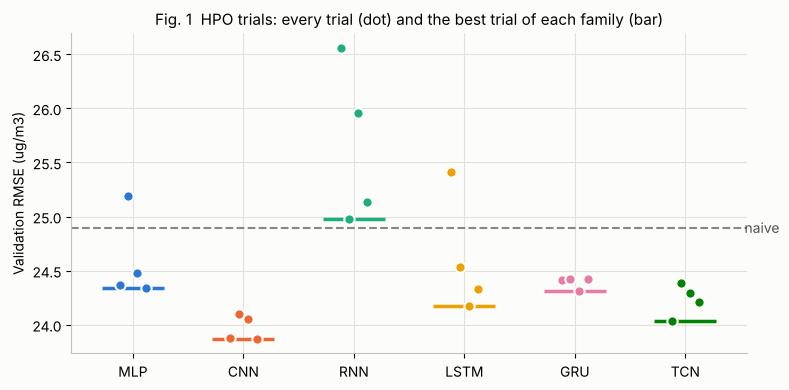

In [26]:
fig, ax = plt.subplots(figsize=(8, 4))
for i, fam in enumerate(FAMILIES):
    d = trials[trials.family == fam]
    ax.scatter(np.full(len(d), i) + np.linspace(-0.12, 0.12, len(d)), d.val_RMSE, s=55, color=COLORS[fam],
               edgecolor="#fcfcfb", linewidth=1.5, zorder=3)
    ax.hlines(d.val_RMSE.min(), i - 0.28, i + 0.28, color=COLORS[fam], lw=2.5, zorder=2)
ax.axhline(baseline_val_rmse, color=COLORS["Naive"], ls="--", lw=1.5)
ax.text(len(FAMILIES) - 0.5, baseline_val_rmse, " naive", va="center", color="#52514e")
ax.set_xticks(range(len(FAMILIES)), FAMILIES)
ax.set_ylabel("Validation RMSE (ug/m3)")
ax.set_title("Fig. 1  HPO trials: every trial (dot) and the best trial of each family (bar)")
plt.tight_layout(); plt.show()

## 13. Finalist selection (validation only) and locking
By the rule of section 10 the finalist is the family-best configuration with the lowest validation RMSE.

In [27]:
finalist = leader.iloc[0]
runner_up = leader.iloc[1]
gap = runner_up["Val RMSE"] - finalist["Val RMSE"]
print(f"FINALIST: {finalist['Family']} ({finalist['Best config']}), validation RMSE {finalist['Val RMSE']:.3f} "
      f"({finalist['RMSE vs naive (%)']:.2f} % better than naive), {finalist['Parameters']} parameters, refit epochs {finalist['Best epoch']}")
print(f"Runner-up: {runner_up['Family']} ({runner_up['Best config']}), validation RMSE {runner_up['Val RMSE']:.3f} -> gap {gap:.3f} ug/m3 "
      f"({100 * gap / runner_up['Val RMSE']:.2f} %). Each configuration was run once (seed {SEED}), so the gap cannot be compared with seed noise.")

FINALIST: CNN (filters=16, kernel_size=7, lr=0.001), validation RMSE 23.870 (4.13 % better than naive), 3233 parameters, refit epochs 16
Runner-up: TCN (filters=8, kernel_size=3, lr=0.001), validation RMSE 24.032 -> gap 0.163 ug/m3 (0.68 %). Each configuration was run once (seed 42), so the gap cannot be compared with seed noise.


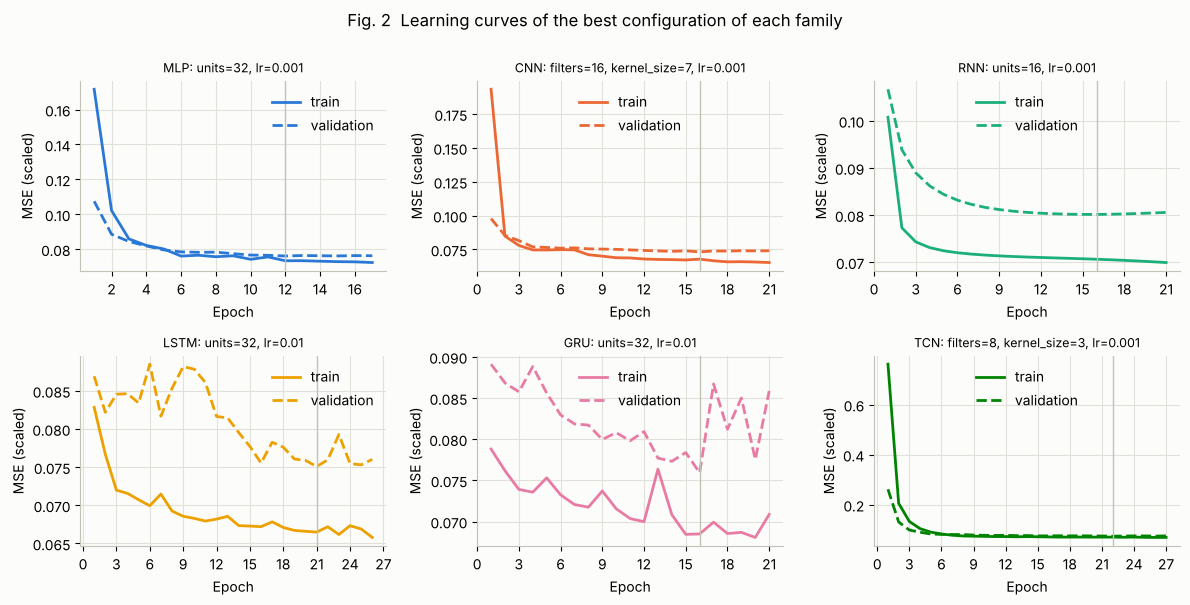

In [28]:
# Learning curves of the best configuration of every family: overfitting check
fig, axes = plt.subplots(2, 3, figsize=(12, 6), sharey=False)
for ax, fam in zip(axes.ravel(), FAMILIES):
    row = leader[leader.Family == fam].iloc[0]
    h = histories[(fam, cfg_key(row["cfg"]), SEED)]
    ep = np.arange(1, len(h["loss"]) + 1)
    ax.plot(ep, h["loss"], color=COLORS[fam], lw=2, label="train")
    ax.plot(ep, h["val_loss"], color=COLORS[fam], lw=2, ls="--", label="validation")
    ax.axvline(row["Best epoch"], color="#c3c2b7", lw=1)
    ax.set_title(f"{fam}: {row['Best config']}", fontsize=9)
    ax.set_xlabel("Epoch"); ax.set_ylabel("MSE (scaled)"); ax.legend()
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
fig.suptitle("Fig. 2  Learning curves of the best configuration of each family", y=1.0)
plt.tight_layout(); plt.show()

### Lock the finalist
The finalist configuration, its refit epoch count, the preprocessing state, the data boundaries and the selection evidence are written to `artifacts/finalist_config.json` **before** any Stage 2 test number is computed.

In [29]:
finalist_config = {
    "locked_before_test_evaluation": True,
    "family": finalist["Family"],
    "config": finalist["cfg"],
    "parameters": int(finalist["Parameters"]),
    "refit_epochs": int(finalist["Best epoch"]),
    "selection": {
        "objective": "validation RMSE (ug/m3), one run per configuration, seed " + str(SEED),
        "tie_break": "fewer parameters",
        "family_best_configurations": leader.drop(columns="cfg").round(4).to_dict("records"),
    },
    "data": {
        "source": DATA_URL, "target": "pm2.5", "unit": "ug/m3", "horizon_hours": 1, "lookback_hours": LOOKBACK,
        "split": "chronological 60/20/20",
        "train": [str(train_raw.index.min()), str(train_raw.index.max())],
        "validation": [str(val_raw.index.min()), str(val_raw.index.max())],
        "test": [str(test_raw.index.min()), str(test_raw.index.max())],
    },
    "preprocessing": {
        "imputer": "forward fill after the chronological split",
        "scaler": "StandardScaler on pm2.5",
        "train_scaler": {"mean": float(scaler.mean_[0]), "scale": float(scaler.scale_[0])},
        "train_plus_validation_scaler": {"mean": float(final_scaler.mean_[0]), "scale": float(final_scaler.scale_[0])},
    },
    "training": {"loss": "mse", "optimizer": "adam", "batch_size": BATCH_SIZE, "max_epochs": MAX_EPOCHS,
                 "early_stopping_patience": PATIENCE, "shuffle": False, "steps_per_execution": STEPS_PER_EXEC,
                 "tcn_dilations": list(TCN_DILATIONS), "tcn_dropout": TCN_DROPOUT},
    "seed": SEED,
    "environment": {"python": platform.python_version(), "tensorflow": tf.__version__, "keras": keras.__version__,
                    "numpy": np.__version__, "pandas": pd.__version__, "scikit_learn": sklearn.__version__},
}
with open(ARTIFACTS / "finalist_config.json", "w") as f:
    json.dump(finalist_config, f, indent=2)
save_log()
print("Locked:", finalist_config["family"], finalist_config["config"], "| refit epochs:", finalist_config["refit_epochs"])
print("Written:", sorted(p.name for p in ARTIFACTS.iterdir()))

Locked: CNN {'filters': 16, 'kernel_size': 7, 'lr': 0.001} | refit epochs: 16
Written: ['finalist_config.json', 'hpo_trials.csv']


### Why the CNN was selected (summary of the selection evidence)
- **Grid search (equal budget, 4 configurations per family, one run each):** best validation RMSE per family: CNN 23.87 < TCN 24.03 < LSTM 24.18 < GRU 24.31 < MLP 24.34 < RNN 24.98 (naive 24.90). By the pre-declared rule the lowest value wins, so the finalist is the CNN with `filters=16, kernel_size=7, lr=0.001`. The runner-up is 0.16 ug/m3 behind, and the best two CNN configurations (23.87 and 23.87) differ by 0.004: Stage 1 had picked `filters=8, kernel_size=3` for the CNN, and on this machine the order of these two near-tied configurations flipped (23.874 vs 23.870), which is the kind of difference a single run cannot resolve.
- **Trade-offs:** the CNN is also the cheapest of the sequence models to train (about 21 s per validation trial against 119 s for the TCN and 113 s for the LSTM). The TCN has fewer parameters (1,153 against 3,233). Validation *MAE* does not agree with validation RMSE: the TCN, LSTM, GRU and RNN configurations were at 12.88-13.02, the CNN at 13.25 (column 'Val MAE' of Table 2). The pre-declared objective is RMSE, so the CNN is the finalist; the effect of this choice on the test ranking is discussed in section 16.

## 14. Controlled comparison on the test set (evaluated once)
Each model uses the configuration that won its own validation grid and the epoch count of that validation run. As in Stage 1: new scaler on train + validation, fresh model on all development windows, fixed epochs, no validation data, seed 42, identical test windows for every model. Training time is the refit time; inference time is the prediction time on the whole test set (median of 5 runs, batch 1024) and the latency of one window (median of 100 eager calls).

In [30]:
# the test windows and development windows come from Stage 1 (section 7); check them before use
assert X_dev.shape[1] == LOOKBACK and X_test_final.shape[1] == LOOKBACK
assert len(test_actual) == len(X_test_final) == len(test_naive)
assert abs(mean_squared_error(test_actual, test_naive) ** 0.5 - 22.152) < 5e-3, "naive test RMSE differs from the recorded Stage 1 value"
print("development windows:", X_dev.shape, "| test windows:", X_test_final.shape, "(same arrays as Stage 1)")

selected = leader.set_index("Family")

def mase(actual, pred, training_values):
    scale = np.mean(np.abs(np.diff(np.asarray(training_values))))
    return np.mean(np.abs(np.asarray(actual) - np.asarray(pred))) / scale

def refit_and_test(family, cfg, epochs, seed):
    model = new_model(family, cfg, seed)
    t0 = time.perf_counter()
    model.fit(inputs_for(family, X_dev), y_dev, epochs=epochs, batch_size=BATCH_SIZE, shuffle=False, verbose=0)
    train_s = time.perf_counter() - t0
    Xt = inputs_for(family, X_test_final).astype("float32")
    pred = inverse_1d(model.predict(Xt, batch_size=1024, verbose=0).ravel(), final_scaler)
    runs = []
    for _ in range(5):
        t0 = time.perf_counter(); model.predict(Xt, batch_size=1024, verbose=0); runs.append(time.perf_counter() - t0)
    one = Xt[:1]
    model(one, training=False)                                            # warm-up
    lat = []
    for _ in range(100):
        t0 = time.perf_counter(); model(one, training=False).numpy(); lat.append(time.perf_counter() - t0)
    rec = {"Model": family, "Parameters": int(model.count_params()), "Epochs": epochs,
           "Train time (s)": train_s, "Inference, full test set (ms)": 1000 * float(np.median(runs)),
           "Latency, one window (ms)": 1000 * float(np.median(lat)),
           "MAE": float(mean_absolute_error(test_actual, pred)),
           "RMSE": float(mean_squared_error(test_actual, pred) ** 0.5),
           "MASE": float(mase(test_actual, pred, dev.values))}
    return rec, pred, model

results, test_preds, finalist_model = [], {}, None
for fam in FAMILIES:
    cfg, epochs = dict(selected.loc[fam, "cfg"]), int(selected.loc[fam, "Best epoch"])
    rec, pred, model = refit_and_test(fam, cfg, epochs, SEED)
    results.append(rec); test_preds[fam] = pred
    if fam == finalist_config["family"]:
        finalist_model = model
    print(f"{fam:<4} | {cfg_str(cfg):<42} | {epochs:>2} epochs | train {rec['Train time (s)']:5.0f} s | "
          f"test MAE {rec['MAE']:.3f} RMSE {rec['RMSE']:.3f}", flush=True)
results = pd.DataFrame(results)
results.to_csv(ARTIFACTS / "final_test_results.csv", index=False)

development windows: (35016, 24) | test windows: (8637, 24) (same arrays as Stage 1)


MLP  | units=32, lr=0.001                         | 12 epochs | train     6 s | test MAE 12.326 RMSE 21.666


CNN  | filters=16, kernel_size=7, lr=0.001        | 16 epochs | train    18 s | test MAE 11.836 RMSE 21.431


RNN  | units=16, lr=0.001                         | 16 epochs | train    42 s | test MAE 11.669 RMSE 21.265


LSTM | units=32, lr=0.01                          | 21 epochs | train    99 s | test MAE 11.702 RMSE 21.943


GRU  | units=32, lr=0.01                          | 16 epochs | train   110 s | test MAE 18.205 RMSE 31.407


TCN  | filters=8, kernel_size=3, lr=0.001         | 22 epochs | train   111 s | test MAE 11.689 RMSE 21.174


In [31]:
naive_rec = {"MAE": mean_absolute_error(test_actual, test_naive),
             "RMSE": mean_squared_error(test_actual, test_naive) ** 0.5,
             "MASE": mase(test_actual, test_naive, dev.values)}

acc = [{"Model": "Naive", "MAE": naive_rec["MAE"], "RMSE": naive_rec["RMSE"], "MASE": naive_rec["MASE"],
        "MAE improvement (%)": 0.0, "RMSE improvement (%)": 0.0}]
cost = [{"Model": "Naive", "Config": "last observed hour", "Parameters": 0, "Refit epochs": 0,
         "Train time (s)": 0.0, "Inference, full test set (ms)": 0.0, "Latency, one window (ms)": 0.0}]
for fam in FAMILIES:
    r = results[results.Model == fam].iloc[0]
    acc.append({"Model": fam, "MAE": r.MAE, "RMSE": r.RMSE, "MASE": r.MASE,
                "MAE improvement (%)": 100 * (naive_rec["MAE"] - r.MAE) / naive_rec["MAE"],
                "RMSE improvement (%)": 100 * (naive_rec["RMSE"] - r.RMSE) / naive_rec["RMSE"]})
    cost.append({"Model": fam, "Config": cfg_str(selected.loc[fam, "cfg"]), "Parameters": int(r.Parameters),
                 "Refit epochs": int(r.Epochs), "Train time (s)": r["Train time (s)"],
                 "Inference, full test set (ms)": r["Inference, full test set (ms)"],
                 "Latency, one window (ms)": r["Latency, one window (ms)"]})
acc, cost = pd.DataFrame(acc), pd.DataFrame(cost)
print(f"Table 3  Test accuracy (seed {SEED}; improvement = relative to the naive baseline)")
display(acc.round(3))
print("Table 4  Computational cost (CPU only)")
display(cost.round(3))

Table 3  Test accuracy (seed 42; improvement = relative to the naive baseline)


,Model,MAE,RMSE,MASE,MAE improvement (%),RMSE improvement (%)
0,Naive,11.958,22.152,0.956,0.000,0.000
1,MLP,12.326,21.666,0.986,-3.083,2.191
2,CNN,11.836,21.431,0.947,1.015,3.256
3,RNN,11.669,21.265,0.933,2.412,4.004
4,LSTM,11.702,21.943,0.936,2.136,0.942
5,GRU,18.205,31.407,1.456,-52.245,-41.782
6,TCN,11.689,21.174,0.935,2.245,4.415


Table 4  Computational cost (CPU only)


,Model,Config,Parameters,Refit epochs,Train time (s),"Inference, full test set (ms)","Latency, one window (ms)"
0,Naive,last observed hour,0,0,0.000,0.000,0.000
1,MLP,"units=32, lr=0.001",833,12,6.101,59.193,1.471
2,CNN,"filters=16, kernel_size=7, lr=0.001",3233,16,18.108,69.593,3.361
3,RNN,"units=16, lr=0.001",305,16,41.614,58.838,32.564
4,LSTM,"units=32, lr=0.01",4385,21,98.934,115.412,42.880
5,GRU,"units=32, lr=0.01",3393,16,110.005,104.839,59.808
6,TCN,"filters=8, kernel_size=3, lr=0.001",1153,22,110.710,139.641,24.826


In [32]:
# Reproducibility check against the Stage 1 numbers recorded in section 7 (other machine)
stage1_recorded = pd.DataFrame({"Model": ["MLP", "CNN"], "Stage 1 test RMSE (recorded)": [21.499, 21.674],
                                "Stage 1 test MAE (recorded)": [12.008, 11.954]})
stage2_rerun = pd.DataFrame({
    "Model": ["MLP", "CNN"],
    "Stage 2 config": [cfg_str(selected.loc[f, "cfg"]) for f in ("MLP", "CNN")],
    "Stage 2 test RMSE": [results[results.Model == f].RMSE.iloc[0] for f in ("MLP", "CNN")],
    "Stage 2 test MAE": [results[results.Model == f].MAE.iloc[0] for f in ("MLP", "CNN")],
})
display(stage1_recorded.merge(stage2_rerun, on="Model").round(3))
print("Stage 1 selected: MLP units=32, lr=0.001 | CNN filters=8, kernel_size=3, lr=0.001")

,Model,Stage 1 test RMSE (recorded),Stage 1 test MAE (recorded),Stage 2 config,Stage 2 test RMSE,Stage 2 test MAE
0,MLP,21.499,12.008,"units=32, lr=0.001",21.666,12.326
1,CNN,21.674,11.954,"filters=16, kernel_size=7, lr=0.001",21.431,11.836


Stage 1 selected: MLP units=32, lr=0.001 | CNN filters=8, kernel_size=3, lr=0.001


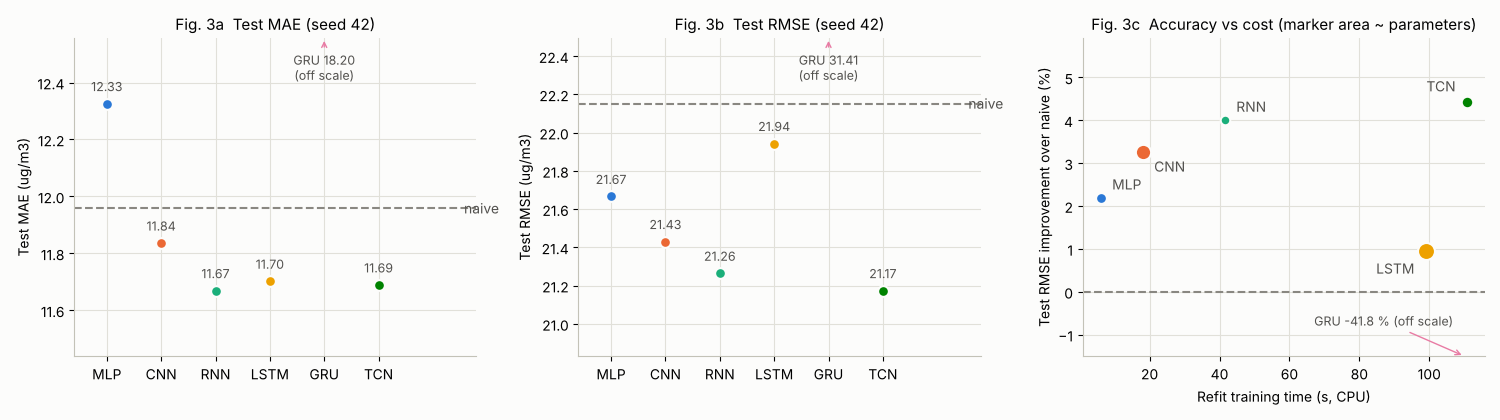

In [33]:
order = ["Naive"] + FAMILIES
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, metric in zip(axes[:2], ["MAE", "RMSE"]):
    # a diverging model must not flatten the scale: the axis covers the models within 15 % of naive, others are marked off scale
    vals = results.set_index("Model")[metric]
    in_range = vals[vals <= 1.15 * naive_rec[metric]]
    lo, hi = min(in_range.min(), naive_rec[metric]), max(in_range.max(), naive_rec[metric])
    top = hi + 0.35 * (hi - lo)
    ax.set_ylim(lo - 0.35 * (hi - lo), top)
    ax.axhline(naive_rec[metric], color=COLORS["Naive"], ls="--", lw=1.5)
    ax.text(len(order) - 0.5, naive_rec[metric], " naive", va="center", color="#52514e")
    for i, name in enumerate(FAMILIES):
        v = vals[name]
        if v in in_range.values:
            ax.scatter(i, v, s=60, color=COLORS[name], edgecolor="#fcfcfb", linewidth=1.5, zorder=3)
            ax.annotate(f"{v:.2f}", (i, v), xytext=(0, 9), textcoords="offset points", ha="center", color="#52514e", fontsize=9)
        else:
            ax.annotate(f"{name} {v:.2f}\n(off scale)", (i, top), xytext=(0, -30), textcoords="offset points", ha="center",
                        color="#52514e", fontsize=9, arrowprops=dict(arrowstyle="->", color=COLORS[name]))
    ax.set_xticks(range(len(FAMILIES)), FAMILIES)
    ax.set_xlim(-0.6, len(order) - 0.2)
    ax.set_ylabel(f"Test {metric} (ug/m3)")
    ax.set_title(f"Fig. 3{'a' if metric == 'MAE' else 'b'}  Test {metric} (seed {SEED})")
LABEL_OFFSET = {"MLP": (8, 6, "left"), "CNN": (8, -14, "left"), "RNN": (8, 6, "left"),
                "LSTM": (-8, -16, "right"), "GRU": (-8, 6, "right"), "TCN": (-8, 8, "right")}
ax = axes[2]
imp = acc.set_index("Model")["RMSE improvement (%)"]
ok = imp[imp >= -15]                                  # models worse than naive by more than 15 % are marked off scale
ymin, ymax = min(ok.min(), 0) - 1.5, ok.max() + 1.5
ax.set_ylim(ymin, ymax)
for fam in FAMILIES:
    r = acc[acc.Model == fam].iloc[0]; c = cost[cost.Model == fam].iloc[0]
    if r["RMSE improvement (%)"] < ymin:
        ax.annotate(f"{fam} {r['RMSE improvement (%)']:.1f} % (off scale)", (c["Train time (s)"], ymin), xytext=(-8, 22),
                    textcoords="offset points", ha="right", color="#52514e", fontsize=9,
                    arrowprops=dict(arrowstyle="->", color=COLORS[fam]))
        continue
    ax.scatter(c["Train time (s)"], r["RMSE improvement (%)"], s=40 + c["Parameters"] / 40, color=COLORS[fam],
               edgecolor="#fcfcfb", linewidth=1.5, zorder=3)
    ax.annotate(fam, (c["Train time (s)"], r["RMSE improvement (%)"]), xytext=LABEL_OFFSET[fam][:2], ha=LABEL_OFFSET[fam][2],
                textcoords="offset points", color="#52514e")
ax.axhline(0, color=COLORS["Naive"], ls="--", lw=1.5)
ax.set_xlabel("Refit training time (s, CPU)"); ax.set_ylabel("Test RMSE improvement over naive (%)")
ax.set_title("Fig. 3c  Accuracy vs cost (marker area ~ parameters)")
plt.tight_layout(); plt.show()

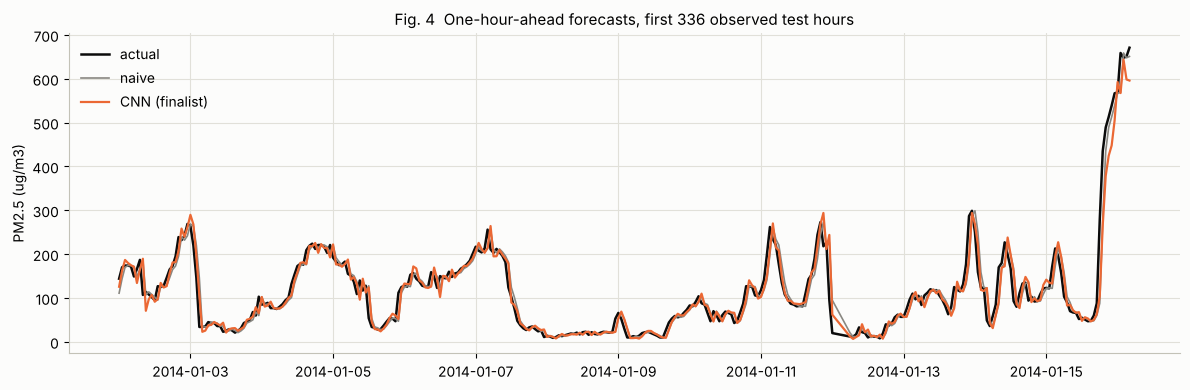

In [34]:
# Forecast overlay on the FIRST 336 observed test targets (first two weeks of 2014; fixed in advance, not cherry-picked)
fam = finalist_config["family"]
dates = test.index[LOOKBACK:][test_observed]
n_show = 336
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(dates[:n_show], test_actual[:n_show], color="#0b0b0b", lw=1.8, label="actual")
ax.plot(dates[:n_show], test_naive[:n_show], color=COLORS["Naive"], lw=1.2, label="naive")
ax.plot(dates[:n_show], test_preds[fam][:n_show], color=COLORS[fam], lw=1.6, label=f"{fam} (finalist)")
ax.set_ylabel("PM2.5 (ug/m3)"); ax.legend()
ax.set_title("Fig. 4  One-hour-ahead forecasts, first 336 observed test hours")
plt.tight_layout(); plt.show()

## 15. Checkpoint for Stage 3 and smoke test
The refit finalist is saved next to the locked configuration and the preprocessing state. The smoke test reloads everything from disk and checks that the pipeline still reproduces the in-memory predictions; it takes a few seconds and trains nothing.

In [35]:
CKPT = ARTIFACTS / "finalist_refit.keras"
finalist_model.save(CKPT)
print("Saved:", CKPT, f"({CKPT.stat().st_size / 1024:.0f} KB)")
print("Artifacts:", sorted(p.name for p in ARTIFACTS.iterdir()))

Saved: artifacts/finalist_refit.keras (67 KB)
Artifacts: ['final_test_results.csv', 'finalist_config.json', 'finalist_refit.keras', 'hpo_trials.csv']


In [36]:
# ---- smoke test: load config + scaler state + checkpoint from disk, predict, compare ----
with open(ARTIFACTS / "finalist_config.json") as f:
    saved = json.load(f)
reloaded = keras.models.load_model(CKPT)

mu, sd = saved["preprocessing"]["train_plus_validation_scaler"]["mean"], saved["preprocessing"]["train_plus_validation_scaler"]["scale"]
assert np.isclose(mu, final_scaler.mean_[0]) and np.isclose(sd, final_scaler.scale_[0])

raw_test = test.to_numpy()                                   # forward-filled test block, original units
scaled_by_hand = (raw_test - mu) / sd                        # preprocessing rebuilt from the saved state only
assert np.allclose(scaled_by_hand, test_scaled_final)

fam = saved["family"]
Xs = inputs_for(fam, X_test_final[:200]).astype("float32")
pred_disk = inverse_1d(reloaded.predict(Xs, verbose=0).ravel(), final_scaler)
assert np.allclose(pred_disk, test_preds[fam][:200], atol=1e-3)
assert train_raw.index.max() < val_raw.index.min() and val_raw.index.max() < test_raw.index.min()
assert saved["locked_before_test_evaluation"] and saved["refit_epochs"] >= 1
assert set(FAMILIES) == set(results.Model)
assert not np.isnan(results[["MAE", "RMSE"]].to_numpy()).any()
print("Smoke test passed:", fam, saved["config"], "| reloaded model reproduces the in-memory forecasts on 200 test windows")

Smoke test passed: CNN {'filters': 16, 'kernel_size': 7, 'lr': 0.001} | reloaded model reproduces the in-memory forecasts on 200 test windows


## 16. Conclusion and unresolved risk

**Conclusion.** At a one-hour horizon the naive forecast is hard to beat: on the test set it scores MAE 11.96 and RMSE 22.15 ug/m3. Five of the six models improve the RMSE, but only by 1-4 % (Table 3, Fig. 3): TCN 4.4 %, RNN 4.0 %, CNN 3.3 %, MLP 2.2 %, LSTM 0.9 %. The MAE gains are smaller: RNN 2.4 %, TCN 2.2 %, LSTM 2.1 %, CNN 1.0 %, while the MLP is 3.1 % worse than naive. Every model was trained and tested once (seed 42), so these small differences come from a single run on a single test year and we cannot say how much of them is seed noise. As a reference for that noise: the MLP with the same configuration as in Stage 1 scored test RMSE 21.67 here against 21.50 recorded in Stage 1 (other machine and library versions), a difference of 0.17 ug/m3, which is as large as most gaps between the better models.

**Finalist chosen from validation evidence only.** The CNN (`filters=16, kernel_size=7, lr=0.001`, 3,233 parameters, 16 refit epochs) won the pre-declared rule: the best validation RMSE of any family (23.87 against 24.03 for the TCN, 24.18 for the LSTM, 24.31 for the GRU, 24.34 for the MLP and 24.98 for the RNN; naive 24.90). The margin to the runner-up is 0.16 ug/m3 (0.7 %), and with one run per configuration it cannot be compared with seed noise, so the choice is supported only weakly. The CNN is also the cheapest of the sequence models to train (refit 18 s against 111 s for the TCN and 99 s for the LSTM on this CPU).

**What the test set shows, and what we did not do with it.** The locked finalist is not the test winner. The TCN and RNN have a lower test RMSE than the CNN (21.17 and 21.26 against 21.43), and the RNN, TCN and LSTM a lower MAE (11.67, 11.69, 11.70 against 11.84). We did not change the finalist after seeing this: that would use the test set for selection, which the protocol forbids. The same pattern appeared in Stage 1 (validation winner not test winner). Two observations help to read it:
- On validation, the TCN, LSTM, GRU and RNN configurations already had a lower MAE (12.88-13.02) than the CNN (13.25) while having a higher RMSE (Table 2). The RMSE objective therefore favoured the CNN, while the recurrent models and TCN were ahead on typical hours. The test MAE ranking has the same order. The RNN even had the worst validation RMSE of all families (24.98, slightly worse than naive) but the best test MAE.
- Validation (2013) and test (2014) are two single one-year blocks, so a ranking decided on one block need not transfer to the other.

**Failure observed.** The GRU (`units=32, lr=0.01`) failed in the final refit: test RMSE 31.41 and MAE 18.20, much worse than naive (-42 % RMSE, Fig. 3). Its validation loss was already unstable at this learning rate (Fig. 2, GRU panel: it jumps between epochs, and the selected epoch 16 is followed by a rise), while the refit trains for a fixed number of epochs with no validation data to stop on. A refit that ends on a bad epoch is the likely cause, but we did not test this, and with a single seed we cannot say whether it is specific to seed 42. The LSTM at the same learning rate shows similar noise in its validation curve and also has the weakest test RMSE gain among the stable models.

**Cost.** MLP and CNN are the cheapest (refit 6 s and 18 s; single-window latency 1.5 ms and 3.4 ms). RNN, LSTM, GRU and TCN need 42-111 s to refit, and in eager mode a single window takes 25-60 ms on these models, against 1.5-3.4 ms for MLP and CNN (Table 4). Times are CPU measurements from this session (2 cores) and are only comparable with each other.

**Unresolved risk.** The ranking of the families depends on one validation block, one training run per configuration, and the metric used for selection. The finalist chosen by validation RMSE did not rank first on test, and the spread between the stable models is about 2 % of the RMSE, of the same order as the run-to-run difference observed for the MLP. Next step before Stage 3: fix the primary metric in advance, repeat the top candidates with several seeds, and select with several chronological validation blocks (rolling origin) instead of one year, so that the Transformer and the final candidates are compared on evidence that is less tied to 2013. For recurrent models at lr 0.01, also use a lower learning rate or a stopping rule in the refit.

## Notes for the repository

**Contribution log (to be completed by the group).**

| Member | Stage 2 work | Commits |
|---|---|---|
| | | |
| | | |
| | | |
| | | |

**Tool-use disclosure.** The Stage 2 code and text (sections 9-16) were drafted with Claude (Anthropic) as a coding assistant. Every number, table and figure above is produced by the executed cells of this notebook. The Stage 2 outputs were generated in a CPU-only Linux session (see section 9); Stage 1 outputs were recorded earlier on a different machine.

**References.** UCI Beijing PM2.5 data (Liang et al., 2015) via the `pollution.csv` copy linked in section 3; TensorFlow/Keras; Assignment 3 (TCN residual block and receptive-field formula, course material).